# Data checks and study design

**Goal.** Confirm what the data can support before any modelling.

**Design choices.** Only fields known at application are used. Only 36-month loans issued from 2013 to 2015 are used, because later loans had not all reached maturity when the data ended.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, json, os
sys.path.insert(0, "../scripts")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from common import *
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e6e3", "font.size": 10})
ACC, MUTE, INK, BAD = "#20808D", "#9a9a94", "#2b2b2b", "#C8452F"
os.makedirs("../outputs/charts", exist_ok=True); os.makedirs("../outputs/tables", exist_ok=True)
def save_metrics(k, v):
    p = "../outputs/metrics.json"; m = json.load(open(p)) if os.path.exists(p) else {}
    m[k] = v; json.dump(m, open(p, "w"), indent=2, default=float)


In [2]:
d = load(); print(d.shape, "defaults", int(d.target.sum()), "rate", round(d.target.mean(), 4), "from", d.issue_month.min().date(), "to", d.issue_month.max().date())
print("duplicate rows:", d.drop(columns=["issue_month", "grade"]).duplicated().sum())

(1345310, 42) defaults 268559 rate 0.1996 from 2007-06-01 to 2018-12-01


duplicate rows: 0


## Maturity bias

The file contains resolved loans only. A 36-month loan issued in 2016 could only appear by the end of 2018 if it had already defaulted or been paid off early, so recent default rates are inflated.

,issue_month,loans,default_rate
23,2013Q1,17988,0.126
24,2013Q2,23136,0.128
25,2013Q3,27318,0.122
26,2013Q4,31980,0.119
27,2014Q1,34074,0.129
28,2014Q2,37881,0.135
29,2014Q3,40595,0.136
30,2014Q4,50020,0.145
31,2015Q1,56568,0.148
32,2015Q2,64222,0.154


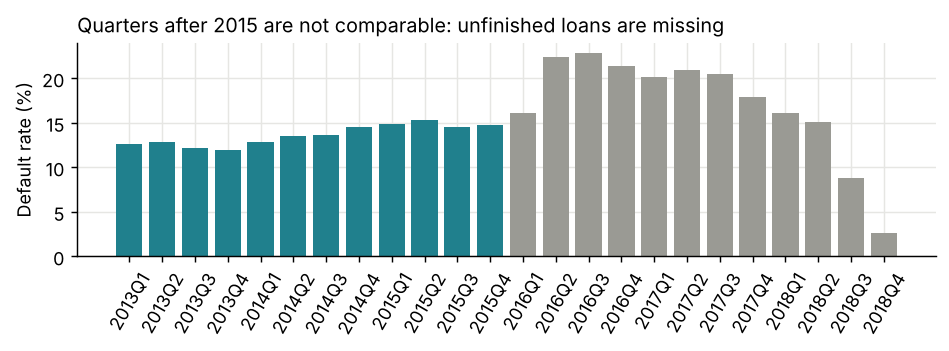

In [3]:
q = d[d.term_num == 36].groupby(d.issue_month.dt.to_period("Q")).target.agg(loans="size", default_rate="mean").reset_index()
q["issue_month"] = q.issue_month.astype(str); q = q[q.issue_month >= "2013Q1"]; q.to_csv("../outputs/tables/vintage_default_rates.csv", index=False); display(q.round(3))
fig, ax = plt.subplots(figsize=(7.4, 2.8)); ax.bar(q.issue_month, 100 * q.default_rate, color=[ACC if v < "2016Q1" else MUTE for v in q.issue_month]); ax.tick_params(axis="x", rotation=60)
ax.set_ylabel("Default rate (%)"); ax.set_title("Quarters after 2015 are not comparable: unfinished loans are missing", loc="left", fontsize=11); plt.tight_layout(); plt.savefig("../outputs/charts/vintage_default_rates.png"); plt.show()

## Leakage screen

A field that uses information after approval usually predicts default too well. No single application field exceeds 0.60 here, which fits application-time data. FICO scores below 0.5 only because higher FICO means lower risk.

In [4]:
from sklearn.metrics import roc_auc_score as auc
s = prepare(d); rows = []
for c in RAW_NUM + ["int_rate", "sub_grade_num"]:
    v = s[c].fillna(s[c].median()); a = auc(s.target, v); rows.append(dict(field=c, auc=a, strength=max(a, 1 - a)))
screen = pd.DataFrame(rows).sort_values("strength", ascending=False); screen.to_csv("../outputs/tables/leakage_screen.csv", index=False); display(screen.head(8).round(3))
print("Strongest single field:", screen.iloc[0].field, round(screen.iloc[0].strength, 3))

,field,auc,strength
17,sub_grade_num,0.667,0.667
16,int_rate,0.659,0.659
15,fico_avg,0.401,0.599
1,annual_inc,0.424,0.576
13,tot_hi_cred_lim,0.425,0.575
14,total_bc_limit,0.425,0.575
6,bc_open_to_buy,0.425,0.575
5,avg_cur_bal,0.428,0.572


Strongest single field: sub_grade_num 0.667


## Study split

The test period is later than the training period, so the score is judged on loans it could not have seen. The validation period sets calibration and cutoffs, and the test period is used once.

In [5]:
sp = s.groupby("split").agg(loans=("target", "size"), defaults=("target", "sum"), default_rate=("target", "mean"), avg_rate=("int_rate", "mean"), first=("issue_month", "min"), last=("issue_month", "max")).reindex(["train", "validation", "test"]).reset_index()
sp.to_csv("../outputs/tables/study_split.csv", index=False); display(sp.round(4))
print(s[RAW_NUM].isna().mean().sort_values(ascending=False).head(6).round(4))
save_metrics("data", dict(rows=len(d), defaults=int(d.target.sum()), study_rows=len(s), strongest_field=screen.iloc[0].field, strongest_auc=screen.iloc[0].strength, splits=sp.drop(columns=["first", "last"]).to_dict("records")))

,split,loans,defaults,default_rate,avg_rate,first,last
0,train,262992,34693,0.1319,12.8097,2013-01-01,2014-12-01
1,validation,120790,18269,0.1512,11.5079,2015-01-01,2015-06-01
2,test,162236,23863,0.1471,11.1043,2015-07-01,2015-12-01


mths_since_recent_inq    0.1061
bc_util                  0.0105
bc_open_to_buy           0.0099
mths_since_recent_bc     0.0092
avg_cur_bal              0.0000
dti                      0.0000
dtype: float64
